# Explain a Trade Space

`EvaluateTradeSpace` counted samples: a point is sufficiently sampled if it is observed at least four times a day. But four samples minutes apart say less than four spread over the day. This notebook measures sampling by its purpose, then explains why designs differ.

It covers:

* a second objective, from the **sampling error** of each point;
* **revisit statistics**, which explain the difference between the two objectives;
* **sensitivity**: which decisions drive each objective.

It imports the design space and study of `EvaluateTradeSpace` from `trade_space_example.py`, beside the notebooks.

## Measure the Sampling Error

Suppose that the observations estimate the daily mean of a field that varies within hours, such as convective precipitation. A point is **accurately sampled** if the mean of its samples estimates the daily mean with an error of at most half the field's standard deviation. Samples closer together than the field's **decorrelation time** (here, 3 hours) repeat each other, so they add little. `estimate_sampling_error` estimates the error at each point from the times of its samples.

The new metrics function (`sample`) gives both shares. `study.replace` copies the study with the new metrics. The copy is a new study, which evaluates every design again, from the cached observations.

In [1]:
from datetime import timedelta

import matplotlib.pyplot as plt
import pandas as pd

from trade_space_example import DURATION, N_POINTS, SAMPLES_PER_DAY, START, describe, designs, planes_name, space, study
from tatc.analysis import estimate_sampling_error
from tatc.tradespace import summarize

DECORRELATION_TIME = timedelta(hours=3)  # of the field whose daily mean is estimated
MAX_RELATIVE_ERROR = 0.5  # of an accurate sample, in standard deviations of the field


def sample(observations, decorrelation_time=DECORRELATION_TIME):
    """The shares (%) of points sampled sufficiently and accurately."""
    if len(observations) == 0:  # no satellites
        return {"sufficient": 0.0, "accurate": 0.0}
    samples = observations.groupby("target_hash").size()
    end = START + DURATION
    error = estimate_sampling_error(observations, START, end, decorrelation_time)
    return {
        "sufficient": 100 * (samples >= SAMPLES_PER_DAY).sum() / N_POINTS,
        "accurate": 100 * (error.relative_error <= MAX_RELATIVE_ERROR).sum() / N_POINTS,
    }


accuracy_study = study.replace(metrics=sample)
results = accuracy_study.run(designs)
summary = summarize(results, ["satellites", "planes", "sufficient", "accurate"])
summary["description"] = summary.apply(describe, axis=1)

The figure compares the two shares of every design. A design on the dashed line samples as many points accurately as sufficiently.

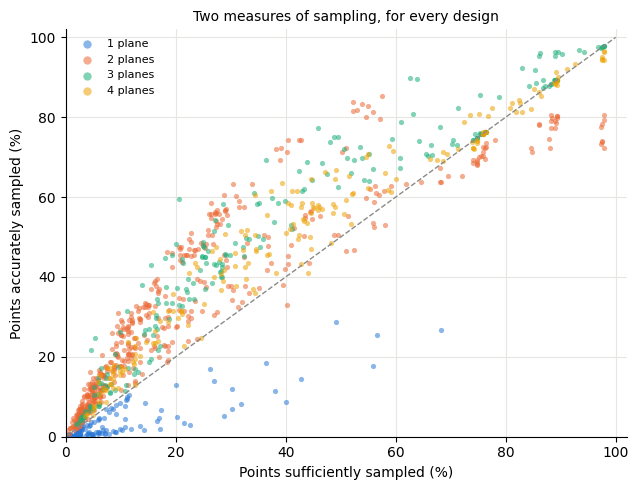

In [2]:
from tatc.tradespace import plot_designs, style_axes
from tatc.tradespace.plotting import GRAY

fig, ax = plt.subplots(figsize=(6.5, 5))
plot_designs(summary, "sufficient", "accurate", by="planes", names=planes_name, legend="upper left", ax=ax)
ax.plot([0, 100], [0, 100], color=GRAY, lw=1, ls="--")
ax.set(xlabel="Points sufficiently sampled (%)", ylabel="Points accurately sampled (%)", xlim=(0, 102), ylim=(0, 102))
style_axes(ax, grid="both")
ax.set_title("Two measures of sampling, for every design", fontsize=10)
fig.tight_layout()
plt.show()

Designs in one plane (blue) fall far below the line: they sample many points four times a day, but few of them accurately. Designs in two or more planes lie near the line or above it.

## Find the Efficient Designs by Accuracy

With the share accurately sampled as the third objective, in place of the share sufficiently sampled, the efficient designs change:

In [3]:
from tatc.tradespace import pareto_front

ACCURACY = {"satellites": "min", "planes": "min", "accurate": "max"}
summary["pareto"] = pareto_front(summary, ACCURACY)
summary[summary.pareto].sort_values(["satellites", "planes"])[
    ["description", "satellites", "planes", "sufficient", "accurate", "accurate se"]
].round(1)

,description,satellites,planes,sufficient,accurate,accurate se
1050,"800 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,3.0,4.2,0.6
1047,"800 km, 60 deg FOR, SSO: 2 at 06:00",2.0,1.0,11.6,10.4,0.9
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,30.2,34.2,1.8
1019,"800 km, 60 deg FOR, Walker 75 deg: 1 x 3 (spac...",3.0,1.0,26.2,17.0,1.1
1075,"800 km, 60 deg FOR, SSO: 2 at 15:00, 1 at 09:00",3.0,2.0,28.8,60.6,1.3
1001,"800 km, 60 deg FOR, Walker 60 deg: 3 x 1 (spac...",3.0,3.0,34.2,61.0,3.8
1020,"800 km, 60 deg FOR, Walker 75 deg: 1 x 4 (spac...",4.0,1.0,49.2,28.6,2.1
1081,"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",4.0,2.0,57.6,85.4,0.7
758,"700 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...",6.0,3.0,89.0,96.4,0.5
1045,"800 km, 60 deg FOR, Walker 75 deg: 4 x 2 (spac...",8.0,4.0,97.8,96.6,0.5


Thirteen designs are efficient by accuracy, against seven by sufficiency, and the designs that spread their samples over the day join the front:

* two satellites in two Walker planes sample 34% of the points accurately, three times as many as two in one plane (10%);
* three satellites in two sun-synchronous planes, or in three Walker planes, sample 61%, against 17% for three in one plane;
* four satellites in two sun-synchronous planes, crossing the equator at 09:00 and 15:00, sample 85%, against 29% for four in one plane;
* six satellites in three planes sample 96%, nearly as many as nine (98%).

## Explain the Difference

Why do designs in one plane sample so few points accurately? Two designs of four satellites show why: the one in a single plane that samples the most points sufficiently, and the one that samples the most points accurately. For the points of the first replicate (`observations_of` and `targets_of` the study):

* `compute_revisit_statistics` gives the times between the samples of each point, and the longest gap of the day;
* `compute_local_time_coverage` gives the number of the eight 3-hour intervals of local time in which each point is sampled.

In [4]:
from tatc.analysis import compute_local_time_coverage, compute_revisit_statistics

four = summary[summary.satellites == 4]
# the design of four satellites in one plane that samples the most points sufficiently, and the design of four that
# samples the most points accurately
chosen = pd.concat([four[four.planes == 1].nlargest(1, "sufficient"), four.nlargest(1, "accurate")])
rows = []
for design, row in zip(space.designs_of(chosen), chosen.itertuples()):
    observations = accuracy_study.observations_of(design)
    points = accuracy_study.targets_of(design)
    revisits = compute_revisit_statistics(observations, START, START + DURATION, targets=points)
    local = compute_local_time_coverage(observations, targets=points)
    sampled = revisits[revisits.samples > 0]
    rows.append(
        {
            "design": row.description,
            "sufficient (%)": row.sufficient,
            "accurate (%)": row.accurate,
            "median revisit (h)": sampled["revisit p50"].dt.total_seconds().median() / 3600,
            "median longest gap (h)": revisits.max_gap.dt.total_seconds().median() / 3600,
            "median 3-h intervals sampled": local.local_bins_sampled.median(),
        }
    )
pd.DataFrame(rows).set_index("design").round(1)

,sufficient (%),accurate (%),median revisit (h),median longest gap (h),median 3-h intervals sampled
design,,,,,
"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spacing 0)",68.2,26.8,0.4,13.8,2.0
"800 km, 60 deg FOR, SSO: 2 at 15:00, 2 at 09:00",57.6,85.4,5.9,7.6,4.0


Satellites that follow each other in one plane pass over a point minutes apart, then leave it for most of the day. The four satellites in one Walker plane sample 68% of the points at least four times a day, but only 27% accurately: half of their revisits are 0.4 hours apart, and they leave a gap of 13.8 hours. The four satellites in two sun-synchronous planes sample fewer points four times (58%), but 85% accurately: their samples are 5.9 hours apart, in four of the eight 3-hour intervals of the day.

## Find What Drives the Objectives

`sensitivity` estimates the share of the variance of each objective, over the designs, that each decision explains. The summary keeps the decisions of each design as columns, named by their paths (such as `layout.walker.planes`). A decision of one alternative is judged among the designs that have it (their share is `active`): the Walker decisions among the Walker designs. The shares are adjusted for what a decision would explain by chance.

In [5]:
from tatc.tradespace import sensitivity

decisions = [
    "altitude",
    "field_of_regard",
    "layout",
    "layout.walker.inclination",
    "layout.walker.planes",
    "layout.walker.per_plane",
    "layout.walker.relative_spacing",
    "layout.sso.planes.count",
]
sensitivity(summary, decisions, ["sufficient", "accurate"]).round(2)

,sufficient,accurate,active
variable,,,
field_of_regard,0.25,0.25,1.00
layout.walker.per_plane,0.22,0.18,0.64
layout,0.19,0.12,1.00
layout.walker.planes,0.12,0.29,0.64
layout.sso.planes.count,0.10,0.19,0.36
altitude,0.03,0.03,1.00
layout.walker.relative_spacing,0.03,0.06,0.64
layout.walker.inclination,0.00,0.00,0.64


The field of regard explains the most of both objectives (25%), as it sets the swath of every satellite. The layout matters next, but differently for the two objectives. The number of satellites in each Walker plane explains more of sufficiency (22%) than of accuracy (18%), and the number of Walker planes the reverse (12% and 29%), as more planes spread the samples in time. The altitude explains little of either (3%), and the inclination nothing.

## Summary

* What a design achieves depends on how it is measured: counts of samples favor satellites that follow each other in one plane, and the sampling error of a daily mean favors samples spread over the day (`estimate_sampling_error`).
* `study.replace` copies a study with other parts, such as other metrics.
* Revisit statistics and local time coverage (`compute_revisit_statistics`, `compute_local_time_coverage`) explain why designs differ, and `sensitivity` finds the decisions that drive each objective.

The next notebook, `SearchTradeSpace`, finds the efficient designs without evaluating every design.

## Notes

* The sampling error here is that of a model of the field: an exponential correlation in time with a decorrelation time of 3 hours. With a simulation of the field (a nature run), `tatc.analysis.sample_field` and `compare_sampled_means` measure it directly (see `AssessSamplingSufficiency`).